# Prédire la qualité d'un vin de Bordeaux à partir de la météo

*Projet de data science : régression linéaire, sélection de modèle par validation croisée et interprétation statistique.*

## Contexte et objectif

En mars 1990, l'économiste de Princeton **Orley Ashenfelter** affirme qu'on peut prédire la qualité d'un millésime de Bordeaux, et donc son prix, **sans le goûter**, simplement à partir de la météo de l'année de récolte. Les critiques œnologiques crient au scandale (« comme un critique de cinéma qui jugerait un film sans le voir »). Pourtant, sa « Bordeaux equation » a souvent fait mieux que les experts, notamment pour les millésimes 1989 et 1990.

**Objectif :** reconstruire ce modèle, vérifier s'il tient statistiquement, quantifier l'effet de chaque facteur météo sur le prix, puis prédire le prix de millésimes jamais vus (1979 et 1980).

**Données :** 25 millésimes (1952-1978), plus 2 millésimes de test.

| Variable | Description |
|---|---|
| `Price` | **logarithme** du prix moyen du millésime aux enchères de 1990-1991 (variable à prédire) |
| `AGST` | température moyenne pendant la saison de croissance, d'avril à septembre (°C) |
| `HarvestRain` | précipitations pendant les vendanges, en août et septembre (mm) |
| `WinterRain` | précipitations de l'hiver précédent, d'octobre à mars (mm) |
| `Age` | âge du vin en 1983 (années) |
| `Year` | année de récolte |
| `FrancePop` | population française l'année de récolte (milliers d'habitants) |

**Démarche :** analyse exploratoire → modèles de complexité croissante → sélection par **validation croisée** (et non par le R² d'apprentissage) → traitement de la colinéarité → interprétation des coefficients → diagnostic des résidus → prédiction avec intervalles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style='whitegrid')
TEAL, ORANGE = '#0f766e', '#c2410c'

## 1 - Chargement et contrôle des données

In [2]:
data = pd.read_csv('wine.csv')
test = pd.read_csv('wine_test.csv')
print("Apprentissage :", data.shape, "| Test :", test.shape, "| Valeurs manquantes :", data.isna().sum().sum())
data.describe().round(2)

Apprentissage : (25, 7) | Test : (2, 7) | Valeurs manquantes : 0


,Year,Price,WinterRain,AGST,HarvestRain,Age,FrancePop
count,25.00,25.00,25.00,25.00,25.00,25.00,25.00
mean,1965.80,7.07,605.28,16.51,148.56,17.20,49694.44
std,7.69,0.65,132.28,0.68,74.42,7.69,3665.27
min,1952.00,6.20,376.00,14.98,38.00,5.00,43183.57
25%,1960.00,6.52,536.00,16.20,89.00,11.00,46584.00
50%,1966.00,7.12,600.00,16.53,130.00,17.00,50254.97
75%,1972.00,7.50,697.00,17.07,187.00,23.00,52894.18
max,1978.00,8.49,830.00,17.65,292.00,31.00,54602.19


**Deux points de vigilance :**

1. **`Price` est déjà un logarithme** (valeurs entre 6,2 et 8,5). On le modélise donc tel quel, sans reprendre son log. Grâce à cette échelle logarithmique, un coefficient β correspond à un effet **multiplicatif** sur le prix réel, d'environ (e^β − 1) × 100 %.
2. **`Age` et `Year` portent exactement la même information**, comme le montre le calcul ci-dessous :

In [3]:
print("Age + Year =", (data['Age'] + data['Year']).unique())

Age + Year = [1983]


`Age` = 1983 − `Year` pour tous les millésimes : c'est une **colinéarité parfaite**. On ne pourra pas garder les deux variables dans un même modèle (partie 4).

## 2 - Analyse exploratoire

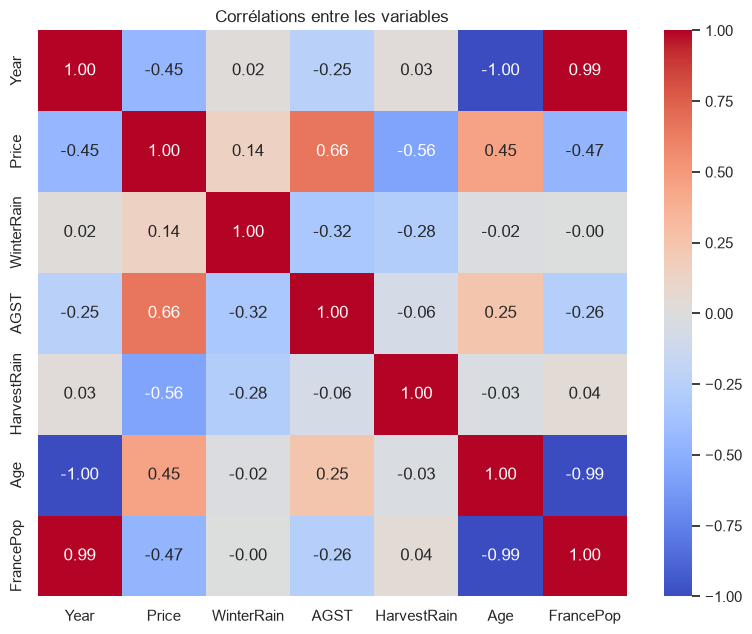

In [4]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Corrélations entre les variables')
plt.tight_layout()
plt.show()

**Constat :** la température de la saison de croissance (`AGST`, +0,66) et la pluie pendant les vendanges (`HarvestRain`, −0,56) sont les variables les plus liées au prix. `Year`, `Age` et `FrancePop` sont quasiment identiques entre elles (corrélations de ±0,99).

### Le prix en fonction de la météo

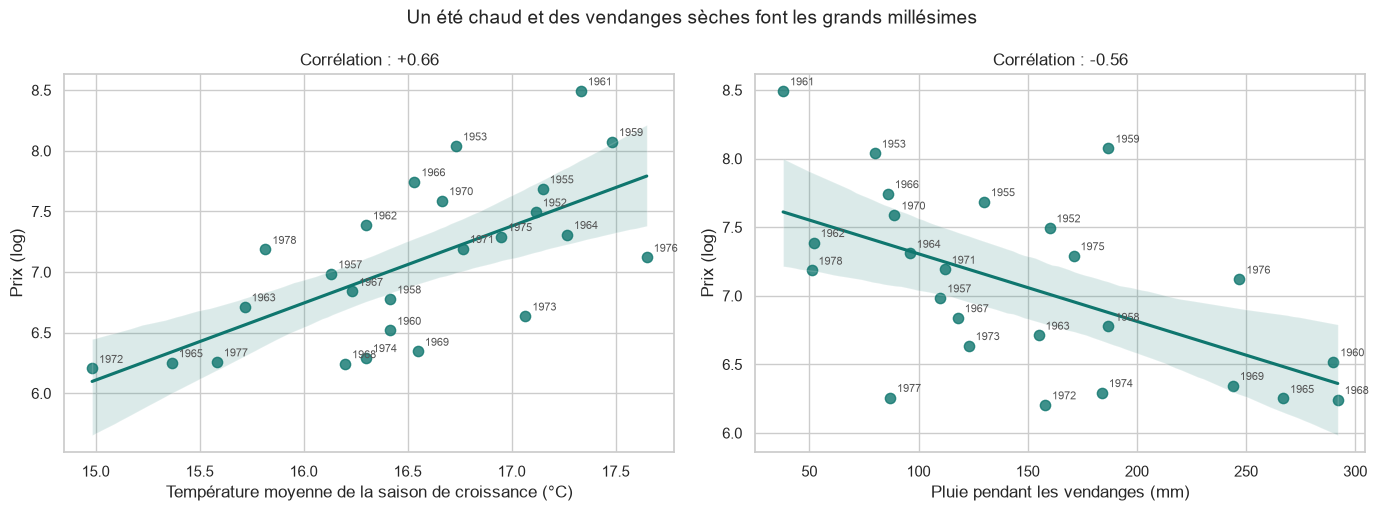

In [5]:
best = data.loc[data['Price'].idxmax()]
f, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, (col, label) in zip(axes, [('AGST', 'Température moyenne de la saison de croissance (°C)'),
                                   ('HarvestRain', 'Pluie pendant les vendanges (mm)')]):
    sns.regplot(data=data, x=col, y='Price', ax=ax, color=TEAL, scatter_kws={'s': 55})
    for _, r in data.iterrows():
        ax.annotate(int(r['Year']), (r[col], r['Price']), textcoords='offset points', xytext=(5, 4), fontsize=8, color='#555')
    ax.set_xlabel(label)
    ax.set_ylabel('Prix (log)')
    rho = data[[col, 'Price']].corr().iloc[0, 1]
    ax.set_title(f"Corrélation : {rho:+.2f}")
f.suptitle('Un été chaud et des vendanges sèches font les grands millésimes', fontsize=14)
plt.tight_layout()
plt.show()

**Constat :** les grands millésimes comme **1961** (le plus cher) et 1953 combinent un été chaud et des vendanges sèches. À l'inverse, 1968 et 1965 cumulent un été frais et des vendanges très pluvieuses. **1959** fait exception : un été record mais des vendanges pluvieuses, et pourtant un prix élevé. Les deux relations semblent bien **linéaires** sur l'échelle logarithmique du prix.

## 3 - Modèles de complexité croissante

Avec seulement 25 millésimes, **le R² calculé sur les données d'apprentissage est trompeur** : il augmente mécaniquement à chaque variable ajoutée, même inutile. Pour comparer honnêtement les modèles, on utilise :
- le **R² ajusté**, qui pénalise le nombre de variables ;
- la **validation croisée leave-one-out (LOO)** : chaque millésime est prédit par un modèle entraîné sur les 24 autres. L'erreur obtenue mesure la capacité à prédire un millésime jamais vu.

In [6]:
data['WinterRain_x_HarvestRain'] = data['WinterRain'] * data['HarvestRain']
test['WinterRain_x_HarvestRain'] = test['WinterRain'] * test['HarvestRain']
y = data['Price']

MODELS = {
    'M1 · température': ['AGST'],
    'M2 · + pluie des vendanges': ['AGST', 'HarvestRain'],
    'M3 · toutes les variables': ['Year', 'WinterRain', 'AGST', 'HarvestRain', 'Age', 'FrancePop'],
    "M4 · équation d'Ashenfelter": ['AGST', 'HarvestRain', 'WinterRain', 'Age'],
    'M5 · + interaction des pluies': ['AGST', 'HarvestRain', 'WinterRain', 'Age', 'WinterRain_x_HarvestRain'],
}

def loo_rmse(cols):
    if not cols:   # modèle de référence : la moyenne des 24 autres millésimes
        pred = np.array([y.drop(i).mean() for i in y.index])
    else:
        pred = cross_val_predict(LinearRegression(), data[cols], y, cv=LeaveOneOut())
    return np.sqrt(((y - pred) ** 2).mean())

rows = [{'Modèle': 'M0 · moyenne (référence)', 'Variables': 0, 'R²': 0.0, 'R² ajusté': 0.0, 'Erreur LOO (RMSE)': loo_rmse([])}]
fits = {}
for name, cols in MODELS.items():
    fits[name] = sm.OLS(y, sm.add_constant(data[cols])).fit()
    rows.append({'Modèle': name, 'Variables': len(cols), 'R²': fits[name].rsquared,
                 'R² ajusté': fits[name].rsquared_adj, 'Erreur LOO (RMSE)': loo_rmse(cols)})
comparison = pd.DataFrame(rows).set_index('Modèle').round(3)
comparison

C:\Users\bibaw\AppData\Local\Temp\ipykernel_32808\4084478665.py:23: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fits[name] = sm.OLS(y, sm.add_constant(data[cols])).fit()


,Variables,R²,R² ajusté,Erreur LOO (RMSE)
Modèle,,,,
M0 · moyenne (référence),0,0.000,0.000,0.664
M1 · température,1,0.435,0.410,0.516
M2 · + pluie des vendanges,2,0.707,0.681,0.391
M3 · toutes les variables,6,0.829,0.784,0.359
M4 · équation d'Ashenfelter,4,0.829,0.794,0.338
M5 · + interaction des pluies,5,0.856,0.818,0.309


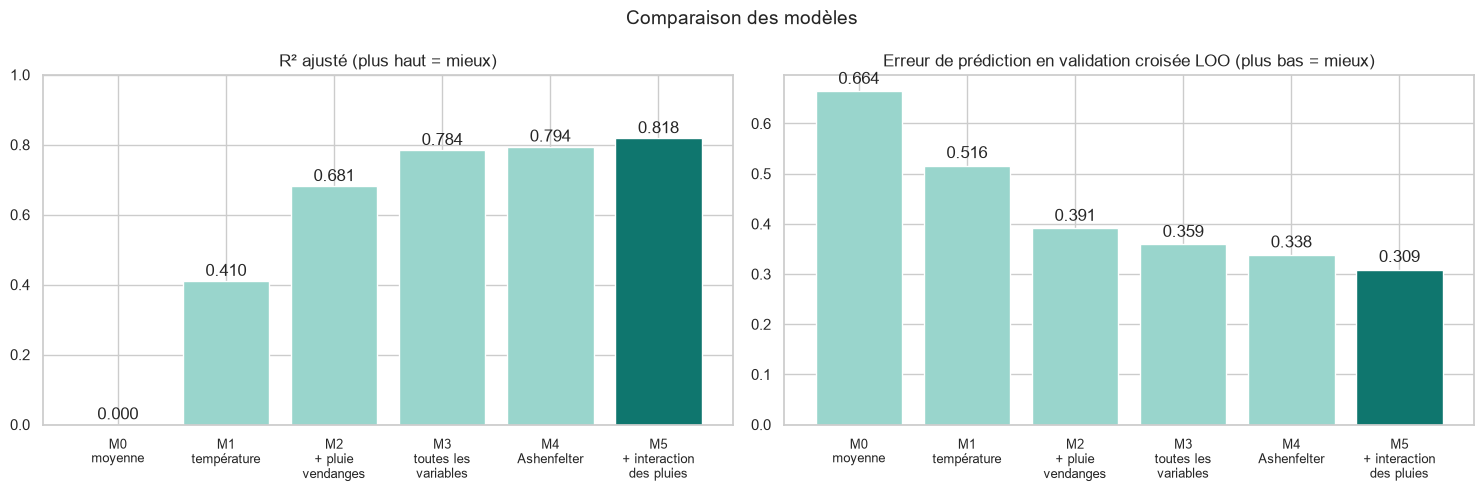

In [7]:
f, axes = plt.subplots(1, 2, figsize=(15, 5))
labels = ['M0\nmoyenne', 'M1\ntempérature', 'M2\n+ pluie\nvendanges', 'M3\ntoutes les\nvariables', 'M4\nAshenfelter', 'M5\n+ interaction\ndes pluies']
colors = [TEAL if m.startswith('M5') else '#99d5cc' for m in comparison.index]

axes[0].bar(labels, comparison['R² ajusté'], color=colors)
axes[0].set_title('R² ajusté (plus haut = mieux)')
axes[0].set_ylim(0, 1)
axes[1].bar(labels, comparison['Erreur LOO (RMSE)'], color=colors)
axes[1].set_title('Erreur de prédiction en validation croisée LOO (plus bas = mieux)')
for ax, col in zip(axes, ['R² ajusté', 'Erreur LOO (RMSE)']):
    for i, v in enumerate(comparison[col]):
        ax.text(i, v + 0.015, f"{v:.3f}", ha='center')
    ax.tick_params(axis='x', labelsize=9)
f.suptitle('Comparaison des modèles', fontsize=14)
plt.tight_layout()
plt.show()

**Constats :**
- **La température seule** (M1) réduit déjà l'erreur de prédiction de 22 % par rapport à la simple moyenne. **Ajouter la pluie des vendanges** (M2) apporte le plus gros gain : le R² passe de 0,43 à 0,71.
- **Mettre toutes les variables** (M3) n'est pas la bonne stratégie. Son R² d'apprentissage (0,829) est identique à celui de M4, mais son erreur LOO est plus élevée (0,359 contre 0,338) : les variables redondantes ajoutent du bruit.
- **L'équation d'Ashenfelter** (M4 : température, pluie des vendanges, pluie d'hiver, âge) explique **83 %** de la variance. Avec l'**interaction entre pluie d'hiver et pluie des vendanges** (M5), on obtient **la plus faible erreur de prédiction** (0,309), soit **2 fois moins que la moyenne** (0,664).

## 4 - Colinéarité

Le facteur d'inflation de la variance (**VIF**) mesure à quel point une variable est redondante avec les autres. Au-delà de 10, la colinéarité est problématique.

In [8]:
X_vif = sm.add_constant(data[['Year', 'WinterRain', 'AGST', 'HarvestRain', 'FrancePop']])
pd.Series({c: variance_inflation_factor(X_vif.values, i) for i, c in enumerate(X_vif.columns) if c != 'const'},
          name='VIF').round(1).to_frame()

,VIF
Year,97.2
WinterRain,1.3
AGST,1.3
HarvestRain,1.1
FrancePop,98.3


**Constat :** `Year` et `FrancePop` ont un VIF proche de 100 : la population française augmente régulièrement avec les années, elle n'apporte aucune information propre. Avec `Age`, la colinéarité est même parfaite (VIF infini, matrice non inversible).

Contrairement à une idée reçue, ce n'est **pas** un problème pour la qualité des prédictions. En revanche, cela rend les **coefficients instables et ininterprétables** : on ne peut pas séparer l'effet de l'âge de celui de la population. On ne garde donc qu'une seule de ces variables, `Age`, la plus parlante : un vin plus vieux est plus rare.

## 5 - Interprétation : combien vaut un degré de plus ?

Pour l'interprétation, on utilise l'équation d'Ashenfelter (M4), où chaque coefficient a un sens direct. Le modèle M5 ajoute une interaction qui rend les effets individuels des pluies plus difficiles à lire.

In [9]:
m4 = fits["M4 · équation d'Ashenfelter"]
print(m4.summary().tables[1])

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -3.4300      1.766     -1.942      0.066      -7.114       0.254
AGST            0.6072      0.099      6.152      0.000       0.401       0.813
HarvestRain    -0.0040      0.001     -4.652      0.000      -0.006      -0.002
WinterRain      0.0011      0.001      2.120      0.047    1.73e-05       0.002
Age             0.0239      0.008      2.956      0.008       0.007       0.041


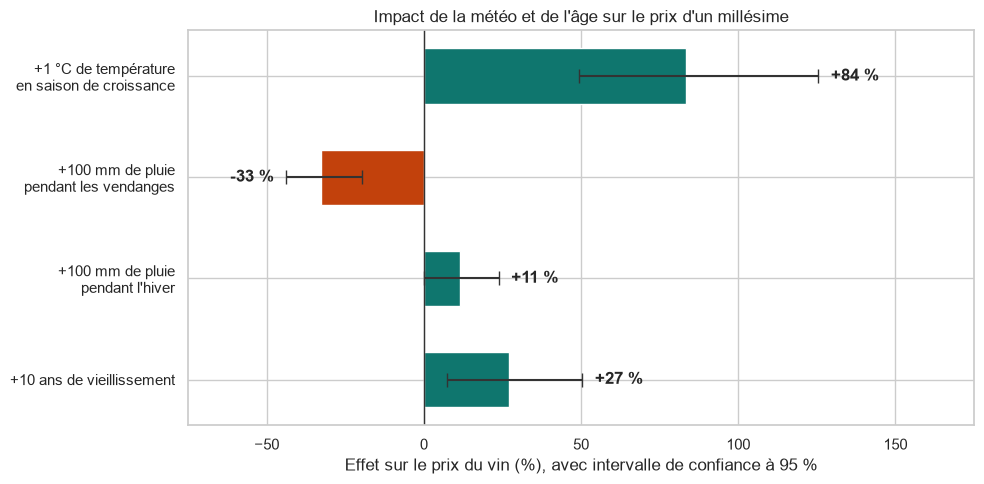

,Effet,Bas,Haut,p-value
+1 °C de température\nen saison de croissance,83.530,49.380,125.488,0.000
+100 mm de pluie\npendant les vendanges,-32.777,-43.744,-19.672,0.000
+100 mm de pluie\npendant l'hiver,11.355,0.174,23.784,0.047
+10 ans de vieillissement,27.037,7.295,50.412,0.008


In [10]:
# Effet de chaque facteur sur le prix réel : exp(β × variation) − 1, avec intervalle de confiance à 95 %
changes = {'AGST': (1, '+1 °C de température\nen saison de croissance'),
           'HarvestRain': (100, '+100 mm de pluie\npendant les vendanges'),
           'WinterRain': (100, "+100 mm de pluie\npendant l'hiver"),
           'Age': (10, '+10 ans de vieillissement')}
ci = m4.conf_int()
effects = pd.DataFrame({
    'Effet': [(np.exp(m4.params[v] * d) - 1) * 100 for v, (d, _) in changes.items()],
    'Bas': [(np.exp(ci.loc[v, 0] * d) - 1) * 100 for v, (d, _) in changes.items()],
    'Haut': [(np.exp(ci.loc[v, 1] * d) - 1) * 100 for v, (d, _) in changes.items()],
    'p-value': [m4.pvalues[v] for v in changes],
}, index=[label for _, label in changes.values()])

f, ax = plt.subplots(figsize=(10, 5))
pos = np.arange(len(effects))[::-1]
ax.barh(pos, effects['Effet'], color=[TEAL if e > 0 else ORANGE for e in effects['Effet']], height=0.55)
ax.errorbar(effects['Effet'], pos, xerr=[effects['Effet'] - effects['Bas'], effects['Haut'] - effects['Effet']],
            fmt='none', ecolor='#333', capsize=5)
for p, (e, h, b) in zip(pos, effects[['Effet', 'Haut', 'Bas']].values):
    x = h + 4 if e > 0 else b - 4
    ax.text(x, p, f"{e:+.0f} %", va='center', ha='left' if e > 0 else 'right', fontweight='bold')
ax.axvline(0, color='#333', linewidth=1)
ax.set_yticks(pos)
ax.set_yticklabels(effects.index)
ax.set_xlim(-75, 175)
ax.set_xlabel('Effet sur le prix du vin (%), avec intervalle de confiance à 95 %')
ax.set_title("Impact de la météo et de l'âge sur le prix d'un millésime")
plt.tight_layout()
plt.show()
effects.round(3)

**Réponses :**
- **La température est le facteur dominant :** à autres conditions égales, **+1 °C** de moyenne pendant la saison de croissance multiplie le prix par environ **1,8 (+84 %)**.
- **La pluie pendant les vendanges est le principal ennemi :** **+100 mm** font baisser le prix d'environ **33 %**. L'eau dilue les raisins juste avant la récolte.
- **La pluie d'hiver est bénéfique** (+11 % pour 100 mm), car elle constitue les réserves en eau de la vigne. L'effet est cependant à la limite de la significativité (p = 0,047).
- **Le vieillissement** ajoute environ **+27 % en 10 ans**.

**Quel facteur compte le plus ?** On ne peut pas comparer les coefficients bruts, car les variables n'ont pas la même unité. La **statistique t** (coefficient divisé par son erreur type) permet de les comparer : `AGST` (t = 6,2) est le facteur le plus déterminant, devant `HarvestRain` (t = −4,7) et `Age` (t = 3,0).

## 6 - Diagnostic des résidus

La régression linéaire suppose des résidus de variance constante (**homoscédasticité**) et de distribution approximativement normale. On le vérifie sur le modèle retenu pour la prédiction (M5).

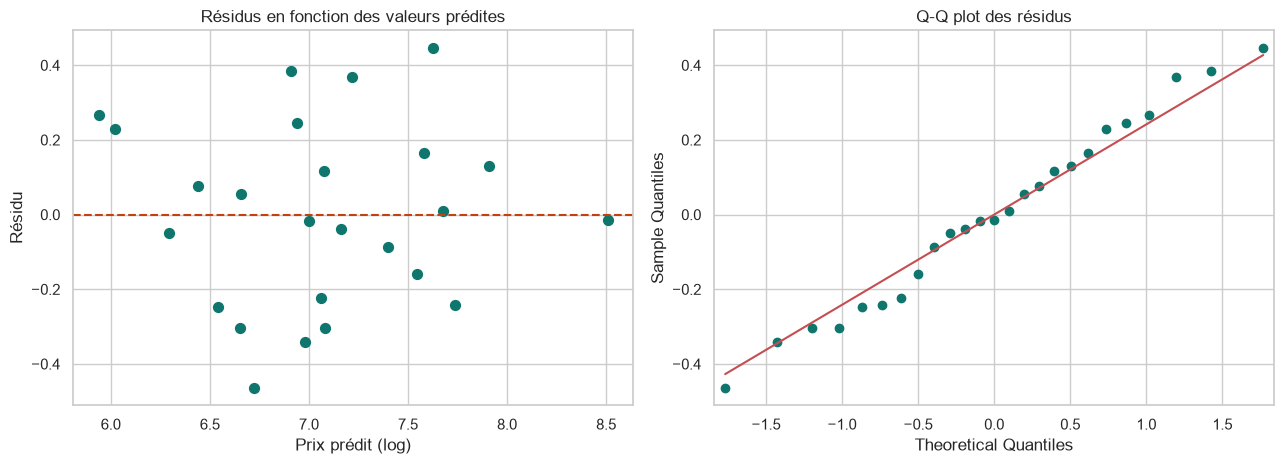

Test de Shapiro-Wilk (normalité) : p = 0.84
Test de Breusch-Pagan (homoscédasticité) : p = 0.69


In [11]:
m5 = fits['M5 · + interaction des pluies']
f, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(m5.fittedvalues, m5.resid, color=TEAL, s=50)
axes[0].axhline(0, color=ORANGE, linestyle='--')
axes[0].set_xlabel('Prix prédit (log)')
axes[0].set_ylabel('Résidu')
axes[0].set_title('Résidus en fonction des valeurs prédites')
sm.qqplot(m5.resid, line='s', ax=axes[1], markerfacecolor=TEAL, markeredgecolor=TEAL)
axes[1].set_title('Q-Q plot des résidus')
plt.tight_layout()
plt.show()

print(f"Test de Shapiro-Wilk (normalité) : p = {stats.shapiro(m5.resid).pvalue:.2f}")
print(f"Test de Breusch-Pagan (homoscédasticité) : p = {sm.stats.het_breuschpagan(m5.resid, m5.model.exog)[1]:.2f}")

**Constat :** les résidus ne présentent pas de structure particulière, et les points du Q-Q plot suivent la droite. Les deux tests ne rejettent pas les hypothèses du modèle (p > 0,05). La régression linéaire est donc adaptée à ces données.

## 7 - Prédiction de nouveaux millésimes : 1979 et 1980

On prédit le prix de deux millésimes absents de l'apprentissage, avec un **intervalle de prédiction à 95 %**. Avec seulement deux points, calculer un R² de test n'aurait pas de sens : on vérifie plutôt que les vrais prix tombent dans les intervalles annoncés.

In [12]:
cols = MODELS['M5 · + interaction des pluies']
pred = m5.get_prediction(sm.add_constant(test[cols], has_constant='add')).summary_frame(alpha=0.05)
result = pd.DataFrame({
    'Millésime': test['Year'],
    'Prix réel (log)': test['Price'],
    'Prix prédit (log)': pred['mean'].values,
    'Intervalle 95 %': [f"[{lo:.2f} ; {hi:.2f}]" for lo, hi in zip(pred['obs_ci_lower'], pred['obs_ci_upper'])],
    'Écart sur le prix réel': [f"{(np.exp(p - r) - 1) * 100:+.0f} %" for p, r in zip(pred['mean'], test['Price'])],
    'Dans l\'intervalle': (test['Price'].values >= pred['obs_ci_lower'].values) & (test['Price'].values <= pred['obs_ci_upper'].values),
}).set_index('Millésime')
result.round(3)

,Prix réel (log),Prix prédit (log),Intervalle 95 %,Écart sur le prix réel,Dans l'intervalle
Millésime,,,,,
1979,6.954,6.648,[6.00 ; 7.30],-26 %,True
1980,6.498,6.532,[5.86 ; 7.20],+3 %,True


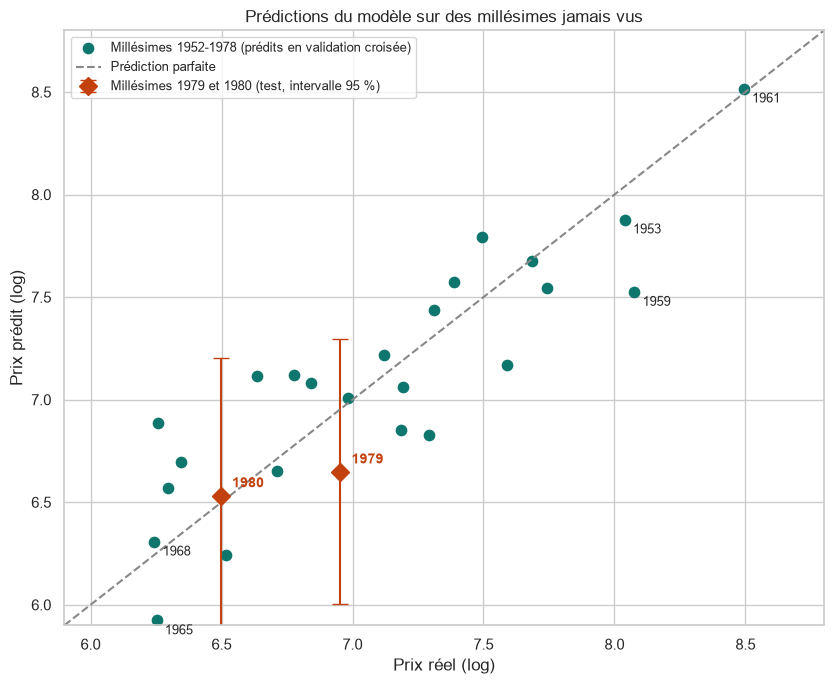

In [13]:
loo_pred = cross_val_predict(LinearRegression(), data[cols], y, cv=LeaveOneOut())

f, ax = plt.subplots(figsize=(8.5, 7))
ax.scatter(y, loo_pred, color=TEAL, s=55, label='Millésimes 1952-1978 (prédits en validation croisée)')
ax.errorbar(test['Price'], pred['mean'], yerr=[pred['mean'] - pred['obs_ci_lower'], pred['obs_ci_upper'] - pred['mean']],
            fmt='D', color=ORANGE, markersize=9, capsize=6, label='Millésimes 1979 et 1980 (test, intervalle 95 %)')
for _, r in data.iterrows():
    if r['Year'] in (1961, 1959, 1953, 1968, 1965, 1972):
        ax.annotate(int(r['Year']), (r['Price'], loo_pred[_]), textcoords='offset points', xytext=(6, -10), fontsize=9)
for yr, real, p in zip(test['Year'], test['Price'], pred['mean']):
    ax.annotate(int(yr), (real, p), textcoords='offset points', xytext=(8, 6), fontsize=10, color=ORANGE, fontweight='bold')
lim = [5.9, 8.8]
ax.plot(lim, lim, '--', color='#888', label='Prédiction parfaite')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Prix réel (log)')
ax.set_ylabel('Prix prédit (log)')
ax.set_title('Prédictions du modèle sur des millésimes jamais vus')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

**Constat :** pour 1979 comme pour 1980, **le prix réel tombe dans l'intervalle de prédiction à 95 %**. Sur l'ensemble des millésimes, le modèle classe correctement les grandes et les petites années, à partir de la seule météo.

Même **1961**, le millésime le plus cher, est prédit presque parfaitement alors que le modèle ne l'a pas vu. La plus grosse erreur concerne **1959**, sous-estimé : ses vendanges pluvieuses auraient dû pénaliser son prix, mais le marché l'a jugé exceptionnel. Le modèle a aussi tendance à surestimer certains petits millésimes. Enfin, les intervalles restent larges, comme le montre 1979 (−26 %) : avec 25 observations, la précision est forcément limitée.

## Conclusion

| Question | Réponse |
|---|---|
| Peut-on prédire la qualité d'un Bordeaux sans le goûter ? | **Oui, en grande partie** : 4 variables (température, pluies, âge) expliquent 83 % de la variance des prix |
| Quel est le facteur le plus important ? | **La température de la saison de croissance** : +1 °C ≈ +84 % de prix |
| Et le plus néfaste ? | **La pluie pendant les vendanges** : +100 mm ≈ −33 % de prix |
| Le modèle généralise-t-il ? | **Oui** : l'erreur de prédiction en validation croisée est 2 fois plus faible que la moyenne, et les prix réels de 1979 et 1980 tombent dans les intervalles à 95 % |

**Leçons de méthode :**
- **Lire la documentation des données** : `Price` était déjà un logarithme, et le reprendre une seconde fois aurait faussé l'interprétation des coefficients.
- **Avec peu de données, comparer les modèles par validation croisée**, pas par le R² d'apprentissage : ajouter toutes les variables donnait le même R² mais de moins bonnes prédictions.
- **La colinéarité ne gêne pas la prédiction, mais l'interprétation** : il faut choisir une variable parmi les redondantes (`Age`, `Year`, `FrancePop`).

**Limites :** 25 observations seulement, donc des intervalles de confiance larges. Certains millésimes atypiques, comme 1959, échappent au modèle. Pistes : ajouter les millésimes récents, des variables viticoles (cépage, appellation) ou une régularisation (Ridge) pour stabiliser les coefficients.